In [1]:
import os
import sys
from numpy import *
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy import interpolate
# import dynamo as dyn
from scipy.integrate import odeint,ode
from scipy import optimize
import astropy.constants as cons
import plot_mesh

sys.path.insert(0, '/home/mozhi/athena/vis/python')
import athena_read

In [2]:
plt.rcParams.update({'font.size': 15})

In [3]:
def complement(data_i):
    tmp = array([data_i[:,0]])
    data_i_new = append(data_i,tmp.T,axis=1)
    return data_i_new

In [4]:
AU = cons.au.cgs.value
YR = (365.2425*24*3600)
M_sun = cons.M_sun.cgs.value
M_e = cons.M_earth.cgs.value
M_j = cons.M_jup.cgs.value
GM_sun = cons.GM_sun.cgs.value
GM_e = cons.GM_earth.cgs.value
GM_J = cons.GM_jup.cgs.value
L_sun = cons.L_sun.cgs.value
sigma_sb = cons.sigma_sb.cgs.value
R_j = cons.R_jup.cgs.value
G = cons.G.cgs.value

In [5]:
# disk slope
T_slope = -0.5
sigma_slope = -1.5
Cs_slope = T_slope/2
H_slope = 1.5+Cs_slope
rho_slope = sigma_slope - H_slope
p_slope = T_slope + rho_slope

# disk parameter
M_star = 1.0 # Msun
M_p = 1.0*M_j/M_e # M_e
a_semi = 5.2 # au, semi-major axis
a0 = 5.2 # r0, reference position of disk temperature/density profile
T_profile = lambda r: 270.0*(r/1.0)**(T_slope)
sigma_profile = lambda r: 1700*(r/1.0)**(sigma_slope)
# default value
T0 = T_profile(a_semi) # Temperature at planet position
Sigma0 = sigma_profile(a_semi) # gas surface density at planet position
UNIT_T = YR/(2*pi)*(a_semi)**(1.5)*M_star**(-0.5) # 1/omega at planet position

print("d_slope=",rho_slope) # midplane gas density slope
print("p_over_d_slope=",p_slope-rho_slope)
print('T0 = ', T0)

d_slope= -2.75
p_over_d_slope= -0.5
T0 =  118.40283260644894


In [6]:
# global dimensionless quantity
mu_He = 4
mu_H2 = 2
mu_xy = 2.34

UNIT_V = sqrt(cons.k_B.cgs.value*T0/(mu_xy*cons.m_p.cgs.value))
UNIT_L = UNIT_V*UNIT_T  # scale height at reference poistion
UNIT_DEN = Sigma0/(sqrt(2*pi)*UNIT_L)
UNIT_PRS = UNIT_DEN*UNIT_V**2
kB_mp_cgs = cons.k_B.cgs.value/cons.m_p.cgs.value
kB_mp = cons.k_B.cgs.value/cons.m_p.cgs.value/(UNIT_V**2)

In [7]:
print("UNIT_V=",UNIT_V)
print("UNIT_L=",UNIT_L)
print("UNIT_T=",UNIT_T)
print("UNIT_DEN=",UNIT_DEN)
print("UNIT_PRS=",UNIT_PRS)
print("KELVIN=",1/kB_mp)

UNIT_V= 64627.27827200537
UNIT_L= 3848894992966.4995
UNIT_T= 59555269.78510755
UNIT_DEN= 1.485996919346557e-11
UNIT_PRS= 0.06206541186995641
KELVIN= 50.59950111386707


In [8]:
print("a")

a


In [9]:
# dimensionless quantity used in intial set-up.
L_norm = (AU/UNIT_L)
r0 = a_semi*(AU/UNIT_L) # planet position/ reference position
phi0 = pi
# m parameter
f_GMp = GM_e / UNIT_T / UNIT_V**3
GMp = f_GMp * M_p*(a_semi/a0)**(-1.5-3*Cs_slope) # WARNING, prefactor 0.085 need to be change accordingly
GM = (r0)**3
GMp0 = GMp*(10/M_p)  # start mass of the planet

In [10]:
# required resolution
rin = 1.0*L_norm
rout = 10.0*L_norm
Nrad = 128
Nphi = 512

In [11]:
# copy to "./athinput.disk_cyl_SMR", all code unit
print("Nondimenional parameters of disk planet problem at",a_semi,"AU: ")
print("rad_planet = r0 = ",r0)
print("phi0 =",phi0)
print("GM =",GM)
print("GMp =",GMp)
print("GMp0 =",GMp0)
print('rin=',rin)
print('rout=',rout)

Nondimenional parameters of disk planet problem at 5.2 AU: 
rad_planet = r0 =  20.211227613680208
phi0 = 3.141592653589793
GM = 8256.159587067685
GMp = 7.880660990343908
GMp0 = 0.24795332408390044
rin= 3.8867745410923473
rout= 38.867745410923476


In [12]:
def face_f_1(x1min,x1max,cell_width_ratio,num_face):
    x = linspace(0,1,num_face)
    tmp = x*(log10(x1max)-log10(x1min)) + log10(x1min)
    
    return 10**(tmp)

In [13]:
from preplot import pol2car, car2pol, v_Intplp2c_xy, dfdx_5pts, dfdx_7pts, curl_in_polar_rlog

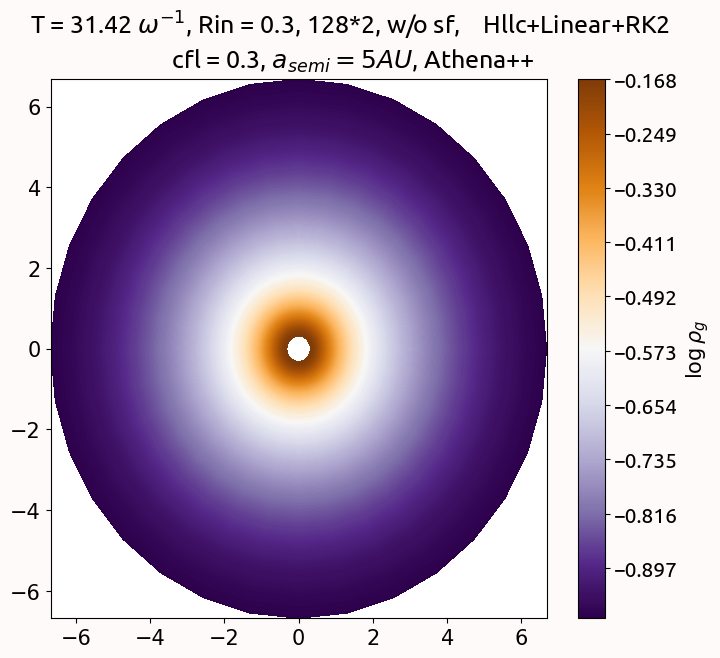

In [14]:
DIR1 = '/home/mozhi/data/flux_test4/'

for nstep in [10]:
    dT = pi
    # read the data
    # rad,phi,z,data = athena_read.vtk('/home/yu/Programs/Athena/work/shear_dust_cooling/planet_shear.joined.out1.'+str(nstep).rjust(5,'0')+'.vtk')
    
    DIR = DIR1
    # DIR = '/home/mozhi/athena/work_gas_only/'
    # DIR = '/home/yu/Programs/Athena/work/output/output97/'
    #----------------------------------------
    # primitive data read
    #----------------------------------------
    data_prim= athena_read.athdf(DIR+'disk.out1.'+str(nstep).rjust(5,'0')+'.athdf', face_func_1=face_f_1)
    rad = data_prim['x1v']  # center of cell in radial direction
    phi = data_prim['x2f']  # center of cell in azimuthal direction
    index_k = 0
    rho_new = complement(data_prim['rho'][index_k,:,:].T)
    prs_new = complement(data_prim['press'][index_k,:,:].T)
    vx1_new = complement(data_prim['vel1'][index_k,:,:].T)
    vx2_new = complement(data_prim['vel2'][index_k,:,:].T)

    # define the grid for arrow plot
    numx = 50
    numy = 50
    x_planet = 0.0
    y_planet = 0.0
    xs = 7.0
    ys = 7.0

    x1_exp = linspace(x_planet-xs,x_planet+xs,numx)
    x2_exp = linspace(y_planet-ys,y_planet+ys,numy)

    # intepolate velocity array to get arrow plot in Cartesian coor.
    vx,vy = v_Intplp2c_xy(rad,phi,x1_exp,x2_exp,vx1_new,vx2_new)
    x1,x2 = pol2car(rad,phi)

    # PLOT
    fig,axes = plt.subplots(nrows = 1, ncols = 1,figsize = (8,7),sharey = True)
    fig.set_facecolor('snow')
    plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=None, hspace=0.2)
    ax = [axes]
    plt.rc('font',family='ubuntu')

    # rho_gas
    ax0 = ax[0].contourf(x1,x2,log10(rho_new),levels = 300,cmap = 'PuOr_r')
    cl = fig.colorbar(ax0,ax = ax[0])
    cl.set_label('$\log \\rho_{g}$')
    
    '''normal = (sqrt(vx**2+vy**2)).max()
    ax[0].streamplot(x1_exp,x2_exp,vx/normal,vy/normal,color = 'grey',linewidth = 1
                   ,arrowstyle = '-', density = 1.0)'''

    R_bondi = 1.0
    R_Hill = 1.0
    # bondi radius
    a = -a_semi
    b = 0.0
    r = R_bondi/L_norm
    theta = arange(0, 2*pi, 0.01)
    x_bondi = a + r * cos(theta)
    y_bondi = b + r * sin(theta)

    x_Hill = a + R_Hill/L_norm*cos(theta)
    y_Hill = b + R_Hill/L_norm*sin(theta)

    '''
    for i in range(len(ax)):
        ax[i].set_xlim(x_planet-xs,x_planet+xs)
        ax[i].set_ylim(y_planet-ys,y_planet+ys)
        ax[i].set_aspect(1)
        ax[i].set_xlabel('$x(AU)$',fontsize =15)
        ax[i].set_ylabel('$y(AU)$',fontsize =15)
        ax[i].plot(x_bondi, y_bondi,'--',linewidth = 1,color = 'blue')
        ax[i].plot(x_Hill, y_Hill,'--',linewidth = 1,color = 'red')
    '''
    

    plt.suptitle('T = %.2f'%(nstep*dT)+' $\omega^{-1}$'+', Rin = 0.3, 128*2, w/o sf,\
    Hllc+Linear+RK2 \n cfl = 0.3, $a_{semi} = 5AU$, Athena++' )

In [15]:
print(data_prim.keys())
plot_time = 280

dict_keys(['Coordinates', 'DatasetNames', 'MaxLevel', 'MeshBlockSize', 'NumCycles', 'NumMeshBlocks', 'NumVariables', 'RootGridSize', 'RootGridX1', 'RootGridX2', 'RootGridX3', 'Time', 'VariableNames', 'x1f', 'x1v', 'x2f', 'x2v', 'x3f', 'x3v', 'rho', 'press', 'vel1', 'vel2', 'vel3'])


In [16]:
rho_ary_time = []
press_ary_time = []
velr_ary_time = []
velphi_ary_time = []


for nstep in range(0,plot_time):
    dT = pi
    # read the data
    # rad,phi,z,data = athena_read.vtk('/home/yu/Programs/Athena/work/shear_dust_cooling/planet_shear.joined.out1.'+str(nstep).rjust(5,'0')+'.vtk')
    
    DIR = DIR1
    # DIR = '/home/yu/Programs/Athena/work/output/output97/'
    #----------------------------------------
    # primitive data read
    #----------------------------------------
    data_prim= athena_read.athdf(DIR+'disk.out1.'+str(nstep).rjust(5,'0')+'.athdf', face_func_1=face_f_1)
    rad = data_prim['x1v']
    rad_bound = data_prim['x1f']
    index_k = 0
    rho_new = data_prim['rho'][index_k,:,:].T
    press_new = data_prim['press'][index_k,:,:].T
    velr_new = data_prim['vel1'][index_k,:,:].T
    velphi_new = data_prim['vel2'][index_k,:,:].T

    rho_ary_time.append(average(rho_new,axis=1))
    press_ary_time.append(average(press_new,axis=1))
    velr_ary_time.append(average(velr_new,axis=1))
    velphi_ary_time.append(average(velphi_new,axis=1))

rho_ary_time = array(rho_ary_time)
press_ary_time = array(press_ary_time)
velr_ary_time = array(velr_ary_time)
velphi_ary_time = array(velphi_ary_time)

In [17]:
flux_in_ary_time = []
flux_out_ary_time = []

for nstep in range(0,plot_time):
    dT = pi
    # read the data
    # rad,phi,z,data = athena_read.vtk('/home/yu/Programs/Athena/work/shear_dust_cooling/planet_shear.joined.out1.'+str(nstep).rjust(5,'0')+'.vtk')
    
    DIR = DIR1
    # DIR = '/home/yu/Programs/Athena/work/output/output97/'
    #----------------------------------------
    # primitive data read
    #----------------------------------------
    data_prim= athena_read.athdf(DIR+'disk.out3.'+str(nstep).rjust(5,'0')+'.athdf', face_func_1=face_f_1)
    index_k = 0
    flux_in_new = data_prim['flx_x1_in'][index_k,:,:].T
    flux_out_new = data_prim['flx_x1_out'][index_k,:,:].T
    flux_in_ary_time.append(average(flux_in_new,axis=1))
    flux_out_ary_time.append(average(flux_out_new,axis=1))
flux_in_ary_time = array(flux_in_ary_time)
flux_out_ary_time = array(flux_out_ary_time)

In this two-dimensional simulation, the $\rho$ of each cell actually denotes the surface density of the disk, since the height of each cell is set to be 1.

To check whether the simulation results are consistent with the actual physical process, I check the distribution of $\rho, p,\Omega, v_r, \dot{M}$ along the radius.
$$\dot{M} = const \propto r^0$$
$$\Omega = \sqrt{\frac{GM}{r^{1.5}}} \propto r^{-1.5}$$
$$\frac{p}{\rho} = c_s^2 \propto T \propto r^{-0.5}$$
$$ \nu = \alpha \frac{c_s^2}{\Omega} \propto r^{1}$$
$$\dot{M} = 3 \pi \nu \Sigma$$
$$\Sigma \propto r^{-1}$$
$$v_r = \frac{3 \nu}{2 r} \propto r^{0}$$

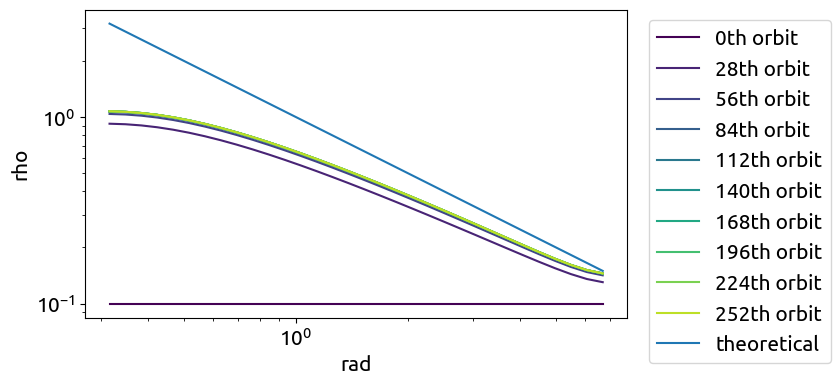

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))

for nstep in range(0,plot_time-1,int(plot_time/10)):
    ax.plot(rad, rho_ary_time[nstep,:], c=plt.cm.viridis(nstep/plot_time),label=f'{nstep}th orbit')
ax.plot(rad,(1.0*(rad/1.0)**(-1)),label = 'theoretical')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('rad')
ax.set_ylabel('rho')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
#plt.ylim(1.0-1.e-4, 1.0+1.e-4)

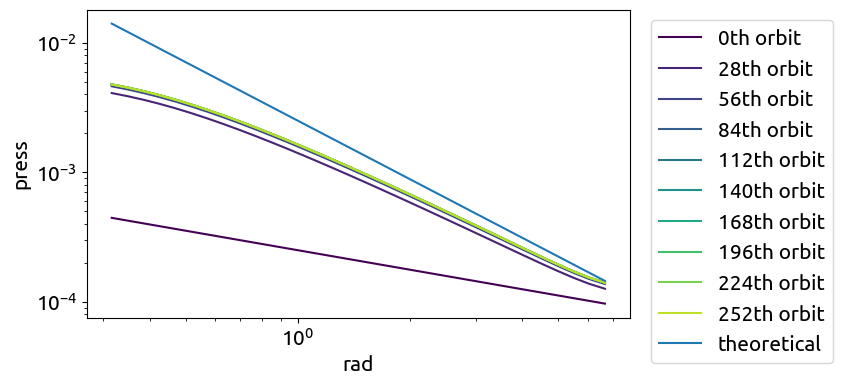

In [19]:
## plot the time evolution of rho, with color of the denoting time:
fig, ax = plt.subplots(figsize=(7, 4))

for nstep in range(0,plot_time,int(plot_time/10)):
    ax.plot(rad, press_ary_time[nstep,:], c=plt.cm.viridis(nstep/plot_time),label=f'{nstep}th orbit')
ax.plot(rad,(1.0*(rad/1.0)**(-1.5)*0.0025),label = 'theoretical')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('rad')
ax.set_ylabel('press')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1))

#plt.ylim(1.0-1.e-4, 1.0+1.e-4)

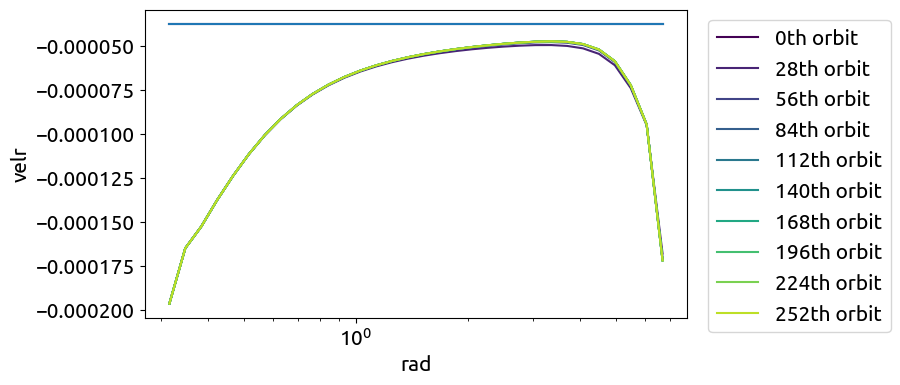

In [20]:
nu_alpha = 1.e-2


## plot the time evolution of rho, with color of the denoting time:
fig, ax = plt.subplots(figsize=(7, 4))

for nstep in range(0,plot_time,int(plot_time/10)):
    ax.plot(rad, velr_ary_time[nstep,:], c=plt.cm.viridis(nstep/plot_time),label=f'{nstep}th orbit')
ax.plot(rad,-1.5*nu_alpha*0.0025*rad**(0))
ax.set_xscale('log')
ax.set_xlabel('rad')
ax.set_ylabel('velr')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1))

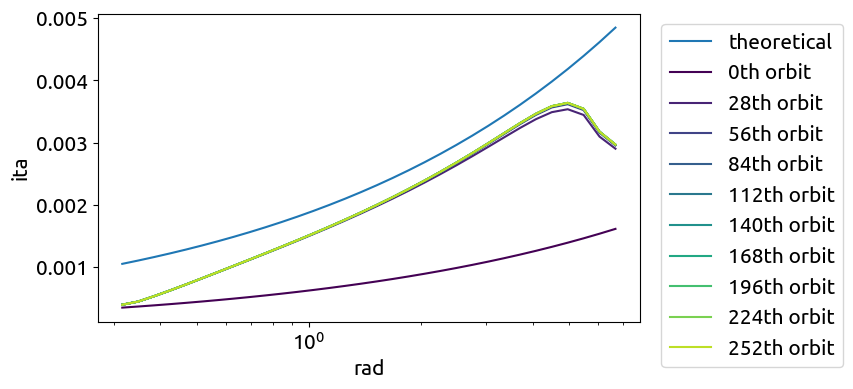

In [29]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(rad,0.5*0.0025*rad**0.5*1.5,label = 'theoretical')
for nstep in range(0,plot_time,int(plot_time/10)):
    ln_r = log(rad)
    ln_p = log(press_ary_time[nstep,:])

    dlnp_dlnr = gradient(ln_p, ln_r)
    ax.plot(rad,-0.5*0.0025*rad**0.5*dlnp_dlnr, c=plt.cm.viridis(nstep/plot_time),label=f'{nstep}th orbit')
ax.set_xscale('log')
ax.set_xlabel('rad')
ax.set_ylabel('ita')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1))

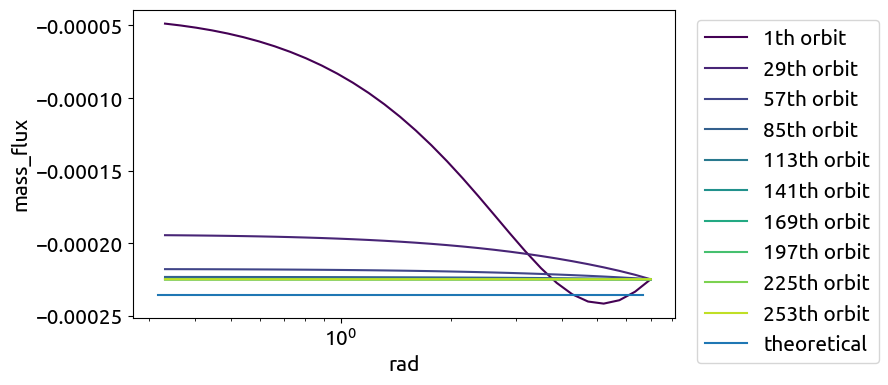

In [30]:
## plot the time evolution of rho, with color of the denoting time:
fig, ax = plt.subplots(figsize=(7, 4))


for nstep in range(1,plot_time,int(plot_time/10)):
    ax.plot(rad_bound[1:], flux_out_ary_time[nstep,:]*2*pi*rad, c=plt.cm.viridis(nstep/plot_time),label=f'{nstep}th orbit')
    #ax.plot(rad,2*pi*rad*rho_ary_time[nstep,:]*velr_ary_time[nstep,:], c=plt.cm.Grays(nstep/plot_time),label=f'{nstep}th orbit')
ax.set_xscale('log')
ax.set_xlabel('rad')
ax.plot(rad,-3*pi*nu_alpha*0.0025*(rad/1.0)**(1)*1.0*(rad/1.0)**(-1.0),label='theoretical')
ax.set_ylabel('mass_flux')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1))

In [25]:
print(3*pi*nu_alpha*0.0025)

0.0002356194490192345


FileNotFoundError: [Errno 2] No such file or directory: '/home/yu/Programs/Athena/work/disk_planet_global/mesh_structure.dat'

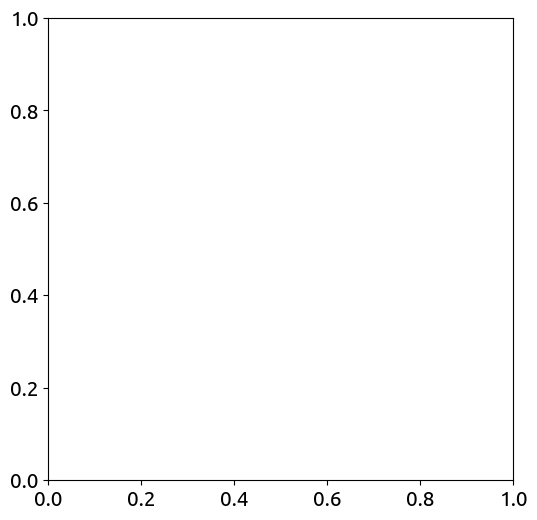

In [23]:
# mesh visualization
fig = plt.figure(figsize=(6,6))
ax = fig.gca()

x = []
y = []
z = []
input_file = '/home/yu/Programs/Athena/work/disk_planet_global/' + 'mesh_structure.dat'
with open(input_file) as f:
    for line in f:
        if line[0] != '\n' and line[0] != '#':
            numbers_str = line.split()
            rad = float(numbers_str[0])/L_norm
            phi = float(numbers_str[1])
            x.append(rad*cos(phi))
            
            y.append(rad*sin(phi))
            # append zero if 2D
            if(len(numbers_str) > 2):
                z.append(float(numbers_str[2]))
            # else:
                # z.append(0.0)
        if line[0] == '\n' and len(x) != 0:
            ax.plot(x, y, z, color = 'black')
            x = []
            y = []
            z = []

In [ ]:
print("a")

: 